Test the slab model with 2 islands. Fig.15 (f):
$$
\begin{align*}
&m_1=2\;,\;m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.5\\
&\iota'=4
\end{align*}
$$

In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

#### Create the magnetic field:

In [2]:
config_id = 23

field = SlabBfieldTwoPert(
    m1=2,
    n1=1,
    delta1=0.5,
    m2=1,
    n2=-1,
    delta2=0.5,
    iota_prime=4.0,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.125 0.75


#### Create the map:

In [3]:
# map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])
map = ToroidalBfieldSection(field, domain=[(0,2), (0, 2*np.pi)], type="dopri5", rtol=1e-10, nsteps=100000)

#### Create Poincaré plot:

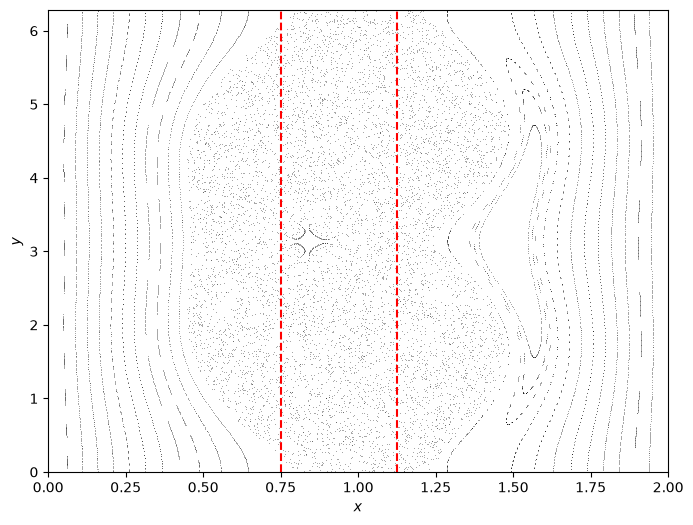

In [4]:
poincare_dir = Path("../../num_results_loc/poincare_plots")
path_poincare = poincare_dir / f"pplot_{config_id}.npz"
with np.load(path_poincare) as data:
    hits = data["hits"].copy()

# Plot directly in (x,y) coordinates
fig, ax = plt.subplots(figsize=(8, 6))

for traj in hits:
    ax.scatter(
        traj[:, 0],
        traj[:, 1],
        color="black",
        marker=".",
        s=0.5,
        lw=0
    )


ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find fixed points:

(<Figure size 800x600 with 1 Axes>, <Axes: >)

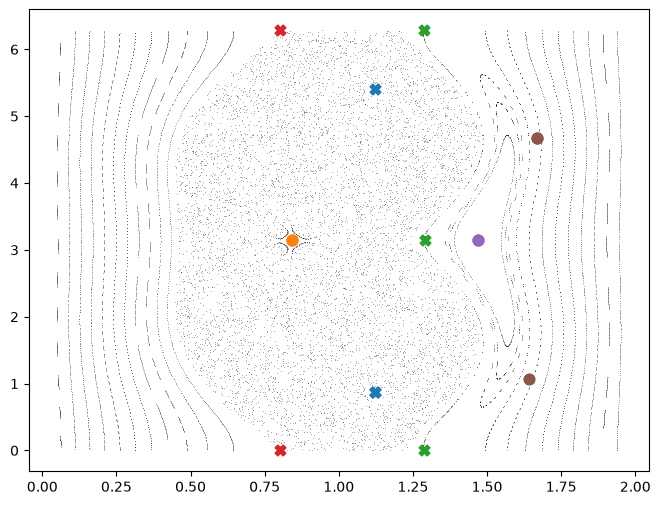

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))

for traj in hits:
    ax.scatter(traj[:, 0], traj[:, 1], color="black", marker=".", s=0.5, lw=0)

fp = FixedPoint(map)

# Elliptic fixed points / O-points:
result = fp.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.3, np.pi]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

result = fp.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

# Hyperbolic fixed points / X-points:
result = fp.find(t = 2, guess = np.array([1.25, 0.]), method="scipy.root")
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

result = fp.find(t = 1, guess = np.array([0.7, 0.]), method="scipy.root")
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

# FP outside of the chaotic region:
result = fp.find(t = 1, guess = np.array([1.5, 3.]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

# # Tried to find X-points of the island structure generated on the right, outside of the chaotic region
result = fp.find(t = 2, guess = np.array([1.5, 6.]), method="scipy.root")   
fp.plot(fig=fig, ax=ax, s=60, plottype=None)

(<Figure size 640x480 with 1 Axes>, <Axes: >)

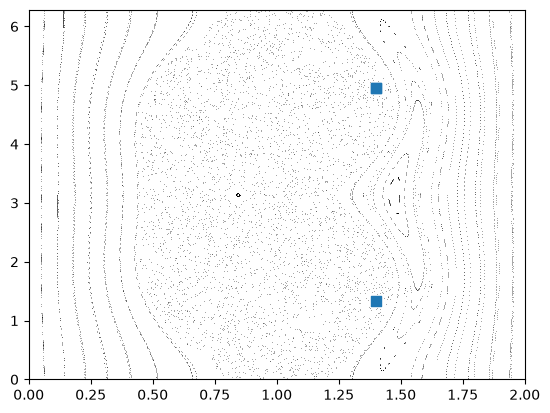

In [148]:

fig, ax = pplot.plot(s=0.5, xlim=[0, 2], ylim=[0, 2*np.pi], plottype=None)

fp = FixedPoint(map)

result = fp.find(t = 2, guess = np.array([1.5, 1.5]), method="scipy.root")
fp.plot(fig=fig, ax=ax, s=60, plottype=None)


#### Find manifolds

In [12]:
# X-points island 1:
fp1 = FixedPoint(map)
fp1.find(t = 2, guess = np.array([1.25, 0.]), method="scipy.root")  

fp2 = FixedPoint(map)
fp2.find(t = 2, guess = np.array(fp1.coords[1]), method="scipy.root")
# fp2.find(t = 2, guess = np.array([1.21, np.pi]), method="scipy.root")

fp3 = FixedPoint(map)
fp3.find(t = 2, guess = np.array([1.287, 6.28]), method="scipy.root")

# X-points island 2:
fp4 = FixedPoint(map)
fp4.find(t = 1, guess = np.array([0.7, 0.]), method="scipy.root")

fp5 = FixedPoint(map)
fp5.find(t = 1, guess = np.array(fp4.coords[1]), method="scipy.root")  

# O-points island 1:
ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.4, np.pi]), method="scipy.root") 

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n1, m = field.m1, guess = np.array(ofp1.coords[1]), method="scipy.root")

# O-points island 2:
ofp3 = FixedPoint(map)
ofp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")

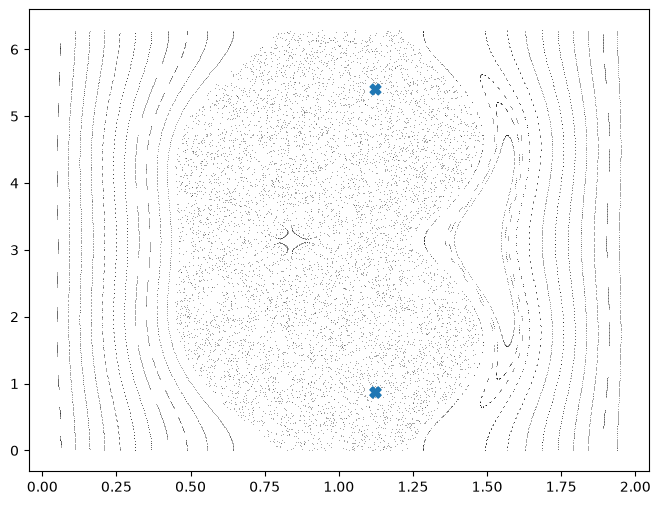

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

for traj in hits:
    ax.scatter(traj[:, 0], traj[:, 1], color="black", marker=".", s=0.5, lw=0)

for fp in [ofp1]:#[fp1, fp2, fp3, fp4, fp5, ofp1, ofp2, ofp3]:
    fp.plot(fig=fig, ax=ax, s=60, plottype=None)

In [13]:
# Island 1 bottom:
manifold1 = Manifold(
    map, fp2, fp1,
    dir1=ofp1.coords[0] - fp2.coords[0],
    dir2=ofp1.coords[0] - fp1.coords[0]
)

manifold2 = Manifold(
    map, fp2, fp1,
    # dir1=ofp1.coords[0] - fp2.coords[0],
    # dir2=ofp1.coords[0] - fp1.coords[0],
    first_stable=False
)

# Island 1 top:
manifold3 = Manifold(
    map, fp2, fp3,
    dir1=ofp2.coords[0] - fp2.coords[0],
    dir2=ofp2.coords[0] - fp3.coords[0]
)

manifold4 = Manifold(
    map, fp2, fp3,
    dir1=ofp2.coords[0] - fp2.coords[0],
    dir2=ofp2.coords[0] - fp3.coords[0],
    first_stable=False
)


# Island 2:
manifold5 = Manifold(
    map, fp4, fp5,
    dir1=ofp3.coords[0] - fp4.coords[0],
    dir2=ofp3.coords[0] - fp5.coords[0]
)

manifold6 = Manifold(
    map, fp4, fp5,
    dir1=ofp3.coords[0] - fp4.coords[0],
    dir2=ofp3.coords[0] - fp5.coords[0],
    first_stable=False
)

In [14]:
for i, manifold in enumerate([manifold1, manifold2, manifold3, manifold4, manifold5, manifold6], start=1):
    manifold.vector_s = np.real_if_close(manifold.vector_s)
    manifold.vector_u = np.real_if_close(manifold.vector_u)

In [ ]:
manifold1.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=4e-3)
stable1_2, unstable1_2 = manifold1.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)

manifold2.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=2.2e-3)
stable2_2, unstable2_2 = manifold2.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)

manifold3.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=2.2e-3)
stable3_2, unstable3_2 = manifold3.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)

manifold4.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=2.2e-3)
stable4_2, unstable4_2 = manifold4.compute_adaptive2(tol=3e-3, n_u_extra=0, n_s_extra=0)

Shifted clinic by (-1, -1) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 1) iterations to the fundamental domain.
Failed to refine clinic at eps_s=2.570895744747442e-07, eps_u=4.984367149635898e-07: in recalculating shifted clinic it escaped the fundamental domain.
Shifted clinic by (-1, 1) iterations to the fundamental domain.
Failed to refine clinic at eps_s=2.89631418495195e-07, eps_u=4.88218762930374e-07: in recalculating shifted clinic it escaped the fundamental domain.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 1) iterations to the fundamental domain.
Homo/hete